(normalization-and-quality)=
# Normalization, filtering and sample quality

Before testing, look at the data: do the samples group as the design expects, which
genes have enough counts to be tested, do the libraries need rescaling, and does any
sample or gene behave unlike the rest? {api}`limma_voom` takes these steps inside,
with defaults; this page takes them one at a time, so that each choice can rest on
what the data show. It uses the CD14+ monocytes of the Kang data [@kang2018] and the
simulated bulk experiment, whose noisier sample is known (the `kang2018` and
`simulated_bulk` datasets of the [Datasets](../reference/datasets.md) page).

## Do the samples group as expected?

limma's multidimensional scaling plot ({api}`plot_mds`) places the samples so that
their distances are the typical log2 fold changes between them, the root mean square
of the 500 largest. From a cube it takes one cell type's counts, filtered and
normalized as edgeR prepares them for its own plot.

CytePool 0.1.dev54+g3f0cbb52e


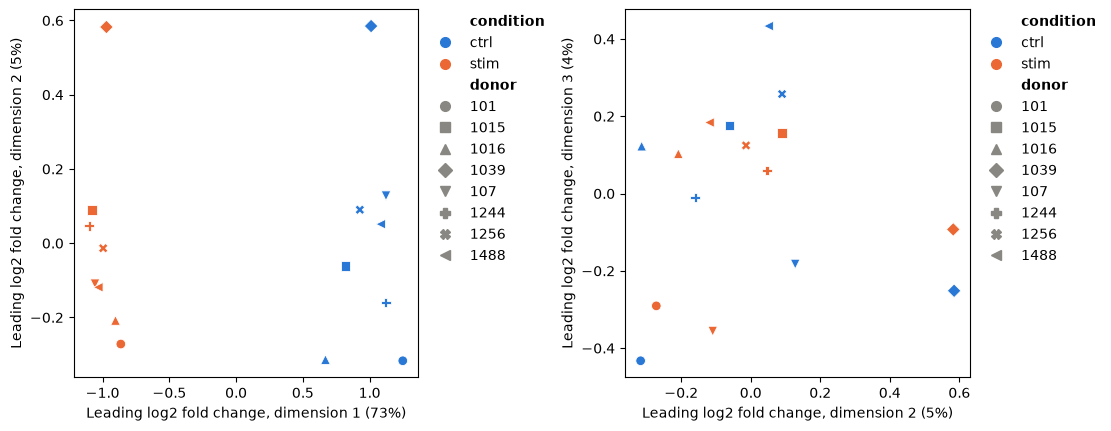

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.io import read_cube
from cytepool.normalization import (
    filter_by_expression,
    median_ratio_size_factors,
    rle_factors,
    tmm_factors,
    upper_quartile_factors,
)
from cytepool.plotting import (
    plot_mds,
    plot_mean_variance,
    plot_residual_variances,
    plot_sample_weights,
)
from cytepool.stats.empirical_bayes import moderated_statistics
from cytepool.stats.linear_models import contrasts_fit, fit_linear_model
from cytepool.stats.voom import voom

kang = read_cube("kang2018.cube.zarr")
print(f"CytePool {cytepool.__version__}")
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, dimensions in ((left, (1, 2)), (right, (2, 3))):
    plot_mds(
        kang,
        group="CD14+ Monocytes",
        color_by="condition",
        marker_by="donor",
        dimensions=dimensions,
        ax=ax,
    )
plt.show()

The first dimension, nearly three quarters of the variation, is the stimulation. The
next ones are the donors: the two samples of each donor lie near each other, and donor
1039 stands apart from the rest. Differences between donors are why the design pairs
each donor's samples ([Genes that change in each cell type](genes_per_cell_type.ipynb)).
A sample far from its group on such a plot deserves a look before any test.

## Which genes to test

voom estimates how the variance of the log counts falls with their level, and weights
every observation by it [@law2014]; its plot ({api}`plot_mean_variance`) shows the
trend. Genes whose counts are mostly zeros have log-CPM
values near the floor in most samples: their spread is small for want of counts, not
because they are precise, and they bend the trend down at its low end, where voom
would then weight noisy observations most. {api}`filter_by_expression` keeps the
genes with enough counts in enough samples, edgeR's `filterByExpr` rule [@chen2016],
and the number of samples it asks for comes from the design.

12,966 genes with counts in at least two samples
 5,125 kept by the filter with the paired design
 3,651 kept by the filter with the condition as the group


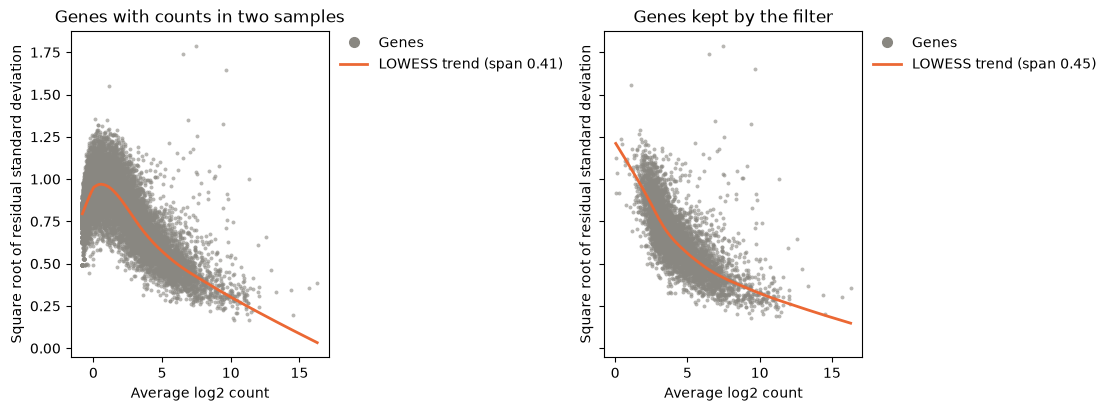

In [2]:
design = Design(
    kang.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
counts = kang.layer("counts", "CD14+ Monocytes")
detected = np.count_nonzero(counts, axis=0) >= 2
keep = filter_by_expression(counts, design=design)
by_condition = filter_by_expression(counts, group=kang.samples["condition"])
print(f"{detected.sum():>6,} genes with counts in at least two samples")
print(f"{keep.sum():>6,} kept by the filter with the paired design")
print(f"{by_condition.sum():>6,} kept by the filter with the condition as the group")

figure, (left, right) = plt.subplots(
    1, 2, figsize=(11, 4), layout="constrained", sharey=True
)
for ax, genes, title in (
    (left, detected, "Genes with counts in two samples"),
    (right, keep, "Genes kept by the filter"),
):
    plot_mean_variance(
        voom(counts[:, genes], design, norm_factors=tmm_factors(counts[:, genes])),
        ax=ax,
    )
    ax.set_title(title)
plt.show()

Without the filter, the trend falls at the low end, as the genes with mostly zero
counts pull it down; with it, the trend falls steadily with the expression level, the
shape voom expects. The number of samples a gene needs comes from the design's
largest leverage: with the paired design, every sample's profile has a leverage of
9/16, so a gene needs enough counts in two samples; with the condition as the group,
in eight, which keeps fewer genes.

## Normalization factors

Library sizes account for sequencing depth, not for composition: when a few genes take
a larger share of a library, every other gene looks lower in it. TMM factors
({api}`tmm_factors`) rescale the libraries so that most genes do not change between
samples [@robinson2010a], and [Count models](../statistics/count_models.md) describes
the alternatives.

In [3]:
stimulated = np.asarray(kang.samples["condition"]) == "stim"
cpm = counts / counts.sum(axis=1, keepdims=True)
gain = cpm[stimulated].mean(axis=0) - cpm[~stimulated].mean(axis=0)
rising = np.argsort(gain)[-20:]
print(
    "The 20 genes that gain most take "
    f"{cpm[~stimulated][:, rising].sum(axis=1).mean():.0%} of the control libraries "
    f"and {cpm[stimulated][:, rising].sum(axis=1).mean():.0%} of the stimulated ones.\n"
)

kept = counts[:, keep]
library_sizes = kept.sum(axis=1)
deseq2 = median_ratio_size_factors(kept) / library_sizes
factors = {
    "TMM": tmm_factors(kept),
    "RLE": rle_factors(kept),
    "upper quartile": upper_quartile_factors(kept),
    "DESeq2": deseq2 / np.exp(np.mean(np.log(deseq2))),
}
print(f"{'median factor':<16}{'control':>9}{'stimulated':>12}")
for name, values in factors.items():
    print(
        f"{name:<16}{np.median(values[~stimulated]):>9.2f}"
        f"{np.median(values[stimulated]):>12.2f}"
    )

The 20 genes that gain most take 4% of the control libraries and 22% of the stimulated ones.

median factor     control  stimulated
TMM                  1.19        0.83
RLE                  1.19        0.84
upper quartile       1.06        0.93
DESeq2               1.19        0.84


Twenty genes that the stimulation raises take a fifth of the stimulated monocytes'
reads, and the factors correct for it: TMM, RLE and DESeq2's size factors agree that
the stimulated libraries count for about 0.83 of their size and the control ones about
1.19, so that without them most genes would look lower after the stimulation. The upper quartile,
which scales each library by one quantile of its counts, corrects less.

## Genes with outlying variances

After voom, the residual variances of the genes should not depend on their expression,
and empirical Bayes moderation shrinks each towards a common prior
([Empirical Bayes moderation](../statistics/empirical_bayes.md)). limma's `plotSA`
({api}`plot_residual_variances`) shows them, and `robust=True` estimates the prior so
that genes with outlying variances do not distort it [@phipson2016].

prior degrees of freedom: 11.4, robust 27.7
largest residual variances: HBB, HBA2, HBA1, ISG15, CCL3, IFITM3, CCL2, CCL4, APOBEC3A, CXCL10, IFI6, LY6E


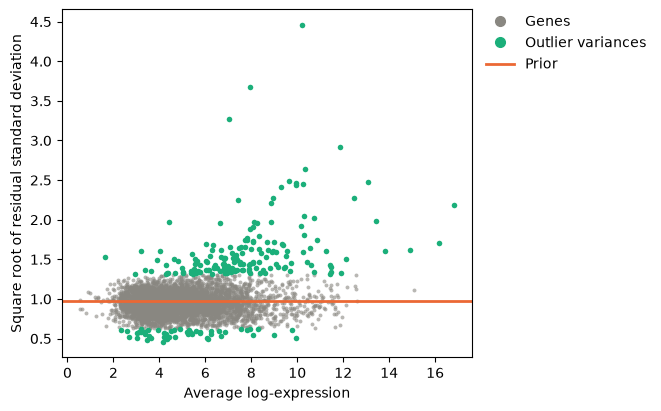

In [4]:
weights = voom(kept, design, norm_factors=tmm_factors(kept))
fit = contrasts_fit(
    fit_linear_model(weights.log_cpm, design, weights=weights.weights),
    design.contrasts,
)
plain, robust = moderated_statistics(fit), moderated_statistics(fit, robust=True)
symbols = np.asarray(kang.features["symbol"])[keep]
print(
    f"prior degrees of freedom: {plain.prior_df:.1f}, robust {np.max(robust.prior_df):.1f}"
)
print(
    "largest residual variances:", ", ".join(symbols[np.argsort(fit.sigma)[-12:][::-1]])
)
plot_residual_variances(robust)
plt.show()

The genes with the largest variances are those of hemoglobin, whose reads come from
red cells that contaminate some samples more than others, and interferon-stimulated
genes and chemokines whose response differs between donors; the plot marks 217
outlying variances. Robust moderation gives such genes smaller prior degrees of
freedom, so that their variances stay closer to their own estimates, and raises those
of the other genes from 11.4 to 27.7, whose variances are then shrunk more, which
gives their tests more power.

## A sample of poor quality

A sample that follows the model less closely than the others, such as a degraded one,
adds noise to every gene. Sample quality weights estimate how closely each sample
follows the model and down-weight it, instead of removing it [@liu2015]; [Precision
weights](../statistics/precision_weights.md) gives the model. In the simulated bulk
experiment, sample `drug_b_3` has four times the dispersion of the others.

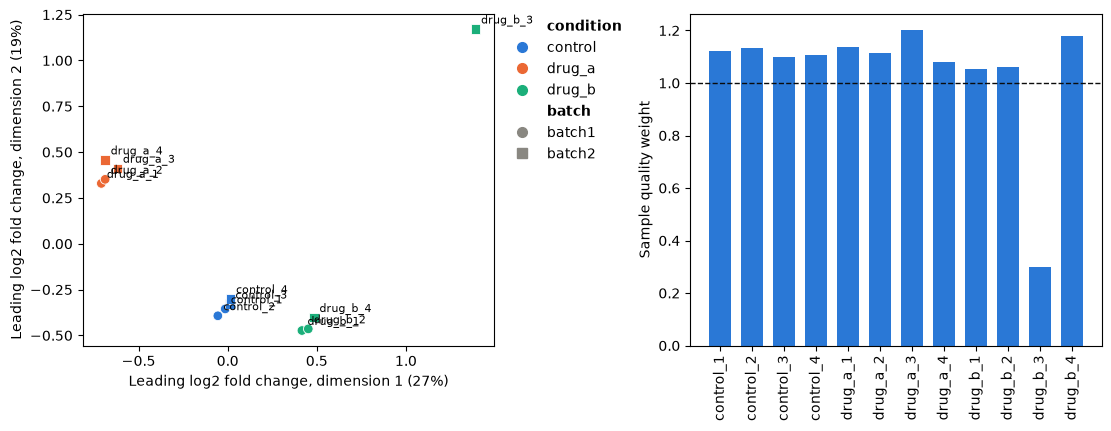

equal weights    192 genes called, 11 of them false
quality weights  204 genes called, 12 of them false


In [5]:
bulk = read_cube("simulated_bulk.cube.zarr")
truth = np.load("simulated_bulk_truth.npz")
bulk_design = Design(
    bulk.samples,
    "~ batch + condition",
    levels={"condition": ["control", "drug_a", "drug_b"]},
    contrasts={"drug_b_vs_control": "conditiondrug_b"},
)
equal = limma_voom(bulk, bulk_design)
weighted = limma_voom(bulk, bulk_design, quality_weights=True)

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
plot_mds(bulk, color_by="condition", marker_by="batch", labels=True, ax=left)
plot_sample_weights(weighted, ax=right)
plt.show()

changed = set(bulk.features["feature_id"][truth["true_log2_fold_change_drug_b"] != 0])
for name, result in (("equal weights", equal), ("quality weights", weighted)):
    table = result.table("bulk", "drug_b_vs_control")
    called = table["feature_id"][table["adjusted_p_value"] < 0.05]
    true = sum(gene in changed for gene in called)
    print(f"{name:<16} {called.size} genes called, {called.size - true} of them false")

The noisy sample stands apart on the MDS plot and gets a weight of 0.30, while the
others weigh slightly more than one, as the weights multiply to one. Down-weighting it
finds more of the genes that drug B changes, with about the same number of false
calls.

## Check the design

A label typed differently in one sample splits a group in two, and the analysis then
runs without an error. {api}`Design.check` reports such problems, with what to do;
here one stimulated sample is labelled `Stim`.

In [6]:
labels = list(kang.samples["condition"])
labels[5] = "Stim"
mislabelled = kang.samples.with_columns(condition=labels)
print(Design(mislabelled, "~ donor + condition").check())

Design check: 16 samples, 10 columns, rank 10, 6 residual degrees of freedom.
3 warnings:
  1. [similar_levels] condition has levels that differ only in case or surrounding
     spaces ('Stim' and 'stim'), and each is a group of its own; if they mean the same
     group, clean the labels before building the design
  2. [single_sample_level] condition has a single sample at level 'Stim' (1016_stim);
     effects of such a level rest on one sample with no replicate. Add replicates, merge
     the level with a similar one, or remove the sample
  3. [unreplicated_sample] the model fits sample 1016_ctrl (donor = 1016, condition =
     ctrl) exactly (leverage 1), so it tells nothing about the residual variance and the
     effects it determines rest on it alone. This happens when a level, or a combination
     of levels in an interaction, has too few samples for the terms that involve it; add
     replicates or simplify the formula


The check also finds aliased and confounded columns, levels without samples, contrasts
the design cannot estimate and numeric codes that look like batches ([Designs, linear
models and contrasts](../statistics/linear_models.md#designs-that-cannot-answer-the-question)).

## Choices

- **The filter.** {api}`limma_voom` filters with the design, as above; a paired design
  gives every sample a high leverage, so a gene needs counts in only a few samples.
  `expression_filter` changes the thresholds, and {api}`filter_by_expression` with
  `group=` asks for counts in as many samples as the smallest group has.
- **Normalization factors.** TMM is the default of {api}`limma_voom` and of edgeR.
  TMM, RLE and DESeq2's median ratios assume that most genes do not change between
  samples, and the upper quartile that one quantile of the counts does not; when a
  response changes many genes, check that the factors make sense, as above.
- **Robust moderation.** Pass `robust=True` to {api}`limma_voom` when `plotSA` shows
  outlying variances, as here.
- **A poor sample.** Quality weights keep it at a lower weight; leaving it out loses
  its information, and in a paired design its partner's ([Precision
  weights](../statistics/precision_weights.md)). `prior_weights="n_cells"` instead
  weights pseudobulk profiles by their number of cells; the two cannot be combined.
- **What to adjust for.** [Repeated measures and donors](repeated_measures.ipynb)
  partitions the variance of every gene among the variables of the design.